# Mission 4: SOFR / Eurodollar FOMC Repricing (Assunta)
Objective: Measure term-structure revisions around FOMC announcements using SOFR futures (Acosta et al. 2024).

In [2]:
import os
import sys
import calendar
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
sys.path.append('..')

## Step 0: Environment Setup & Historical Data Ingestion

In this initial section, I loaded the four core historical datasets:
1. **SOFR 3-Month Futures (sofr_futures_history.csv):**
2. **Eurodollar 3-Month Futures (eurodollar_futures_history.csv):**
3. **FOMC Calendar (fomc_events_history_1990_2026.csv):** 
4. **Reference Benchmark Rates (reference_rates_bloomberg.csv):** 

In [3]:
# Futures SOFR (2018-2028) and Eurodollar (1990-2023)
df_sofr = pd.read_csv('../data/sofr_futures_history.csv', parse_dates=['date'])
df_ed = pd.read_csv('../data/eurodollar_futures_history.csv', parse_dates=['date'])

# Calendar  FOMC from 2010 to 2026)
df_events = pd.read_csv('../data/fomc_events_history_1990_2026.csv', parse_dates=['event_date'])
df_fomc = df_events[
    (df_events['event_type'].str.startswith('FOMC')) &
    (df_events['event_date'] >= '2010-01-01') &
    (df_events['event_date'] <= '2026-11-18')
].sort_values('event_date').reset_index(drop=True)

# EFFR and SOFR
df_ref = pd.read_csv('../data/reference_rates_bloomberg.csv', parse_dates=['date'])

print(f"Rows SOFR: {len(df_sofr)} | Rows Eurodollar: {len(df_ed)} | Meetings FOMC (2010-2026): {len(df_fomc)}")

Rows SOFR: 50509 | Rows Eurodollar: 269536 | Meetings FOMC (2010-2026): 136


I inspected the schema and sample rows of each dataframe (`head(3)` and `columns`) to verify date parsing, contract ticker formatting, and price availability prior to computing CME expiration dates and contract-consistent rate revisions.

In [4]:
print("SOFR Futures")
print(df_sofr.head(3))
print(df_sofr.columns)
print("EURODOLLAR Futures")
print(df_ed.head(3))
print(df_ed.columns)
print("FOMC Events")
print(df_fomc.head(3))
print(df_fomc.columns)

SOFR Futures
        date  px_last  px_settle  px_volume  open_interest contract
0 2018-05-07   97.560     97.560      356.0           56.0   SFRH19
1 2018-05-07   97.290     97.290        NaN            NaN   SFRH20
2 2018-05-07   97.245     97.245        NaN            NaN   SFRH21
Index(['date', 'px_last', 'px_settle', 'px_volume', 'open_interest',
       'contract'],
      dtype='object')
EURODOLLAR Futures
        date  px_last  px_settle  px_volume  open_interest contract
0 1990-01-02  91.9100    91.9100    92926.0            NaN    EDH90
1 1990-01-02  91.7300    91.7300     2709.0            NaN    EDH91
2 1990-01-02  91.4199    91.4199      798.0            NaN    EDH92
Index(['date', 'px_last', 'px_settle', 'px_volume', 'open_interest',
       'contract'],
      dtype='object')
FOMC Events
        event_id event_date      event_type event_time_et  \
0  FOMC_20100127 2010-01-27  FOMC_SCHEDULED           NaN   
1  FOMC_20100316 2010-03-16  FOMC_SCHEDULED           NaN   
2  FOMC

## Step 1: Price cleaning and computation of CME contract expiration dates
Firstly, I defined a function CME_expiry that compute the expiring date CME of a contract ( tuesday before the third wednesday of the month).


Secondly, I cleaned the prices filling the NaN of px_settle with px_last 

In [5]:
month_legend = {'H':3 , 'M':6, 'U':9, 'Z':12}

def CME_expiry(contract_code) -> pd.Timestamp:
    code = contract_code.strip()
    month_char = code[-3]
    year_xx = int(code[-2:])
    if year_xx >= 90:   # 1990-1999
        year = 1900 + year_xx
    else:
        year = 2000 + year_xx  # 2000-2026
    month = month_legend[month_char]
    
    #  3M SOFR (SFR) expiry in +3months
    if code.upper().startswith('SFR'):
        month += 3
        if month > 12:
            month -= 12
            year += 1
            
    cal = calendar.monthcalendar(year, month)
    wednesdays = [week[2] for week in cal if week[2] != 0]
    third_wednesday = pd.Timestamp(year=year, month=month, day=wednesdays[2])
    return third_wednesday - pd.Timedelta(days=1)  # return the day before the third wednesday 


for df in [df_sofr, df_ed]:
    df['price'] = df['px_settle'].fillna(df['px_last'])   # Cleaning price p

# adding the "expiry date" on df_sofr and df_ed
df_sofr['expiry_date'] = df_sofr['contract'].map({c: CME_expiry(c) for c in df_sofr['contract'].unique()})
df_ed['expiry_date'] = df_ed['contract'].map({c: CME_expiry(c) for c in df_ed['contract'].unique()})

print(df_sofr.head())

        date  px_last  px_settle  px_volume  open_interest contract   price  \
0 2018-05-07   97.560     97.560      356.0           56.0   SFRH19  97.560   
1 2018-05-07   97.290     97.290        NaN            NaN   SFRH20  97.290   
2 2018-05-07   97.245     97.245        NaN            NaN   SFRH21  97.245   
3 2018-05-07   97.220     97.220        NaN            NaN   SFRH22  97.220   
4 2018-05-07   97.190     97.190        NaN            NaN   SFRH23  97.190   

  expiry_date  
0  2019-06-18  
1  2020-06-16  
2  2021-06-15  
3  2022-06-14  
4  2023-06-20  


## Step 2: Contract-Consistent FOMC Repricing Calculation (2010–2026)

I followed the methodology of **Acosta et al. (2024)** computing daily implied interest rate revisions ($\Delta f_t^{(n)}$, expressed in basis points) across all 136 FOMC announcements between 2010 and 2026, yielding 408 contract-event observations.

1. For the Eurodollar regime (pre-2022) I selected the 2nd, 3rd and 4th active quarterly Eurodollar contracts meanwhile for SOFR regime (post-2022) I transitioned to 3-month SOFR futures and selected the 3rd, 4th, 5th active quarterly contracts. 
2. For each FOMC date t, **obs_t** maps to the announcement trading session or the next avaiable business day, while **obs_prev** maps to the immediately preceding market close, automatically accounting for weekends and U.S. market holidays.
3. I ranked active contracts chronologically on obs_t to identify the three target tickers. The pre-announcement price $P_{t-1}$ is queried for the exact same contract ticker, eliminating artificial roll jumps when a front contract expires between $t-1$ and $t$.
4. I converted prices into implied forward rates via $f = 100 - P$ (in %), and the daily FOMC repricing shock is computed in basis points as $\Delta f = (f_t - f_{t-1}) \times 100$


In [6]:

# switch date is when we switched from Eurodollar (before 2022) to SOFR (after 2022)
switch_date = pd.Timestamp('2022-01-01')
results = []

ed_trading_dates = np.sort(df_ed['date'].unique()) 
sofr_trading_dates = np.sort(df_sofr['date'].unique())


# for every FOMC meeting between 2010 and 2026
for _, row in df_fomc.iterrows():
    t = row['event_date']
    event_id = row['event_id']
    event_type = row['event_type']
    # following the Acosta methodology:
    if t < switch_date:
        df_curr = df_ed
        trading_dates = ed_trading_dates
        target_indices = [1, 2, 3]  # 2°, 3° and 4° expiring Eurodollar contract 
        instrument_name = 'Eurodollar_3M'
    else:
        df_curr = df_sofr
        trading_dates = sofr_trading_dates
        target_indices = [2, 3, 4]  # 3°, 4° and 5° expiring SOFR contract
        instrument_name = 'SOFR_3M'
        
    valid_t = trading_dates[trading_dates >= t] #trading dates after the meeting t
    valid_prev = trading_dates[trading_dates < t] #trading dates before the meeting t
    if len(valid_t) == 0 or len(valid_prev) == 0:
        continue
    
    obs_t = pd.Timestamp(valid_t[0])   #first day after or current day of the meeting t
    obs_prev = pd.Timestamp(valid_prev[-1])   #previous day of the meeting t


    # selecting active contracts at obs_t
    active_t = (
        df_curr[(df_curr['date'] == obs_t) & (df_curr['expiry_date'] >= obs_t)]
        .dropna(subset=['price'])
        .sort_values('expiry_date')
        .reset_index(drop=True)
    )

    if len(active_t) <= max(target_indices):
        continue

    # block the same identical contract reading the prices
    df_prev_day = df_curr[df_curr['date'] == obs_prev].set_index('contract')
    
    for horizon_rank, idx in enumerate(target_indices, start=2):  # 2=q+2, 3=q+3, 4=q+4
        c_row_t = active_t.iloc[idx]
        c_id = c_row_t['contract']
        
        if c_id not in df_prev_day.index:
            continue
            
        p_t = float(c_row_t['price'])
        p_prev = float(df_prev_day.loc[c_id, 'price'])
        
        if np.isnan(p_t) or np.isnan(p_prev):
            continue
            
        # impilict rate and bp variation
        rate_t = 100.0 - p_t
        rate_prev = 100.0 - p_prev
        change_bp = (rate_t - rate_prev) * 100.0
        
        results.append({
            'observation_date': obs_t.strftime('%Y-%m-%d'),
            'prev_observation_date': obs_prev.strftime('%Y-%m-%d'),
            'fomc_meeting_date': t.strftime('%Y-%m-%d'),
            'event_id': event_id,
            'event_type': event_type,
            'horizon_bucket': f'ED{horizon_rank}_equiv',
            'contract_id': c_id,
            'instrument': instrument_name,
            'source': 'Bloomberg',
            'futures_price_prev': round(p_prev, 4),
            'futures_price': round(p_t, 4),
            'implied_rate_pct': round(rate_t, 4),
            'expected_change_bp': round(change_bp, 2)
        })

# final tab
df_repricing = pd.DataFrame(results)
print(f" total calculated observations: {len(df_repricing)} (across {df_repricing['fomc_meeting_date'].nunique()} meeting FOMC)")
display(df_repricing.tail(9))


 total calculated observations: 408 (across 136 meeting FOMC)


,observation_date,prev_observation_date,fomc_meeting_date,event_id,event_type,horizon_bucket,contract_id,instrument,source,futures_price_prev,futures_price,implied_rate_pct,expected_change_bp
399,2026-07-29,2026-07-28,2026-07-29,FOMC_20260729,FOMC_SCHEDULED,ED2_equiv,SFRZ26,SOFR_3M,Bloomberg,95.895,95.970,4.030,-7.5
400,2026-07-29,2026-07-28,2026-07-29,FOMC_20260729,FOMC_SCHEDULED,ED3_equiv,SFRH27,SOFR_3M,Bloomberg,95.825,95.870,4.130,-4.5
401,2026-07-29,2026-07-28,2026-07-29,FOMC_20260729,FOMC_SCHEDULED,ED4_equiv,SFRM27,SOFR_3M,Bloomberg,95.820,95.845,4.155,-2.5
402,2026-09-16,2026-09-15,2026-09-16,FOMC_20260916,FOMC_SCHEDULED,ED2_equiv,SFRH27,SOFR_3M,Bloomberg,95.525,95.435,4.565,9.0
403,2026-09-16,2026-09-15,2026-09-16,FOMC_20260916,FOMC_SCHEDULED,ED3_equiv,SFRM27,SOFR_3M,Bloomberg,95.395,95.295,4.705,10.0
404,2026-09-16,2026-09-15,2026-09-16,FOMC_20260916,FOMC_SCHEDULED,ED4_equiv,SFRU27,SOFR_3M,Bloomberg,95.355,95.270,4.730,8.5
405,2026-10-28,2026-10-27,2026-10-28,FOMC_20261028,FOMC_SCHEDULED,ED2_equiv,SFRH27,SOFR_3M,Bloomberg,95.520,95.555,4.445,-3.5
406,2026-10-28,2026-10-27,2026-10-28,FOMC_20261028,FOMC_SCHEDULED,ED3_equiv,SFRM27,SOFR_3M,Bloomberg,95.360,95.385,4.615,-2.5
407,2026-10-28,2026-10-27,2026-10-28,FOMC_20261028,FOMC_SCHEDULED,ED4_equiv,SFRU27,SOFR_3M,Bloomberg,95.315,95.320,4.680,-0.5


## Step 3: Cross-Market Validation with U.S. 2-Year Treasury Yields

Because exact intraday announcement windows are unavailable across the full historical calendar, we validate our daily futures repricing series against an independent benchmark sensitive to near-term Federal Reserve policy expectations: the **U.S. 2-Year Treasury Yield** (`treasury_2y_yield.csv`).

1. **Daily 2Y Yield Shock ($\Delta y_{2Y}$):** We compute the daily close-to-close change in the 2-year benchmark yield (in basis points) across all trading days.
2. **Wide-Format Reshaping & Event Alignment:** We pivot `df_repricing` into wide format across our three quarterly maturity buckets (`ED2_equiv`, `ED3_equiv`, `ED4_equiv`) and perform an inner merge with the 2Y Treasury series on the exact announcement trading date (`observation_date`), covering all **136 FOMC meetings (2010–2026)**.
3. **Co-Movement & Extreme Shock Diagnostics:** We evaluate Pearson correlations between each futures horizon and $\Delta y_{2Y}$ to confirm consistent policy-path pricing across money-market futures and sovereign bond markets, and inspect the top five largest FOMC repricing episodes on the $q+3$ (`ED3_equiv`) horizon.

In [7]:
# Loading Treasury 2Y
df_2y = pd.read_csv('../data/treasury_2y_yield.csv', parse_dates=['date']).sort_values('date')
df_2y['yield_2y_prev'] = df_2y['yield_2y_pct'].shift(1)
df_2y['delta_2y_bp'] = (df_2y['yield_2y_pct'] - df_2y['yield_2y_prev']) * 100.0
df_2y['observation_date'] = df_2y['date'].dt.strftime('%Y-%m-%d')

# Tab wide 
df_wide = df_repricing.pivot(
    index=['fomc_meeting_date', 'observation_date', 'instrument'],
    columns='horizon_bucket',
    values='expected_change_bp'
).reset_index()

# 
df_val = pd.merge(
    df_wide,
    df_2y[['observation_date', 'yield_2y_pct', 'delta_2y_bp']],
    on='observation_date',
    how='inner'
)

print(f"Meeting FOMC validated with Treasury 2Y (2010-2026): {len(df_val)}")
for h in ['ED2_equiv', 'ED3_equiv', 'ED4_equiv']:
    corr = df_val[h].corr(df_val['delta_2y_bp'])
    print(f"Correlation {h} vs Δ Treasury 2Y (bp): {corr:.3f}")


print("\n 5 biggest repricing FOMC (horizon q+3):")
display(df_val.reindex(df_val['ED3_equiv'].abs().sort_values(ascending=False).index).head(5))

Meeting FOMC validated with Treasury 2Y (2010-2026): 136
Correlation ED2_equiv vs Δ Treasury 2Y (bp): 0.833
Correlation ED3_equiv vs Δ Treasury 2Y (bp): 0.910
Correlation ED4_equiv vs Δ Treasury 2Y (bp): 0.933

 5 biggest repricing FOMC (horizon q+3):


,fomc_meeting_date,observation_date,instrument,ED2_equiv,ED3_equiv,ED4_equiv,yield_2y_pct,delta_2y_bp
112,2023-12-13,2023-12-13,SOFR_3M,-14.5,-25.0,-30.0,4.4265,-30.43
106,2023-03-22,2023-03-22,SOFR_3M,-10.5,-18.0,-25.0,3.9367,-22.97
113,2024-01-31,2024-01-31,SOFR_3M,-13.5,-16.5,-17.5,4.2067,-12.78
98,2022-03-16,2022-03-16,SOFR_3M,13.0,16.0,17.5,1.9379,8.88
100,2022-06-15,2022-06-15,SOFR_3M,-12.5,-16.0,-19.5,3.1908,-23.59


## Step 4: Historical SOFR–EFFR Basis Spread Diagnostics

To evaluate level consistency across the pre-2022 Eurodollar/Fed Funds regime and the post-2022 SOFR regime, we analyze the empirical spread between the **Secured Overnight Financing Rate (SOFR)** and the **Effective Federal Funds Rate (EFFR)** using official daily fixings (`reference_rates_bloomberg.csv`).

1. **Overlapping Sample Filtering:** We isolate all trading days where both overnight benchmarks are simultaneously published (`2018-04-03` through `2026-11-12`, spanning 2,151 daily observations).
2. **Basis Spread Computation ($\text{SOFR} - \text{EFFR}$):** We compute the daily spread in basis points as $(\text{SOFR}_t - \text{EFFR}_t) \times 100$ and examine its summary distribution (mean, standard deviation, quartiles, and extreme repo-market spikes) to document why first-difference event shocks ($\Delta f_t$) remain invariant to minor level basis adjustments while any level-based curve stitching requires explicit spread calibration.

In [8]:
# Historical analysis of spread SOFR - EFFR 
df_spread = df_ref.dropna(subset=['effr', 'sofr']).copy()
df_spread['sofr_effr_spread_bp'] = (df_spread['sofr'] - df_spread['effr']) * 100.0

print(f"SOFR & EFFR overlapping period: {df_spread['date'].min().date()} -> {df_spread['date'].max().date()}")
print("\nStatistics Spread SOFR - EFFR (in basis points):")
print(df_spread['sofr_effr_spread_bp'].describe().round(2))

SOFR & EFFR overlapping period: 2018-04-03 -> 2026-11-12

Statistics Spread SOFR - EFFR (in basis points):
count    2151.00
mean       -0.17
std         8.17
min       -15.00
25%        -3.00
50%        -1.00
75%         1.00
max       295.00
Name: sofr_effr_spread_bp, dtype: float64


## Step 5: Deliverable Export & Visual Diagnostics

In this final step, we package our results into standardized outputs for integration into the team repository and presentation:

1. **Standardized Dataset Export (`data/sofr_ed_fomc_repricing.csv`):** We export all **408 contract-event observations** following the project's canonical schema (`observation_date`, `fomc_meeting_date`, `contract_id`, `instrument`, `source`, `futures_price`, `implied_rate_pct`, `expected_change_bp`), providing a clean, roll-free panel of FOMC rate surprises across 2010–2026.
2. **Two-Panel Diagnostic Figure (`sofr_fomc_repricing_validation.png`):**
   * **Panel A (Historical Time Series, $q+3$ Horizon):** Displays FOMC implied rate revisions across the Eurodollar (2010–2021) and SOFR (2022–2026) regimes, highlighting the January 2022 transition and major monetary policy inflection points (such as the March 2020 emergency cuts and the 2022–2023 tightening cycle).
   * **Panel B (Cross-Market Validation Scatterplot):** Compares daily futures repricing ($\Delta f_t^{(q+3)}$) against daily changes in the U.S. 2-Year Treasury yield ($\Delta y_{2Y}$) around FOMC announcements relative to the 45-degree parity line.

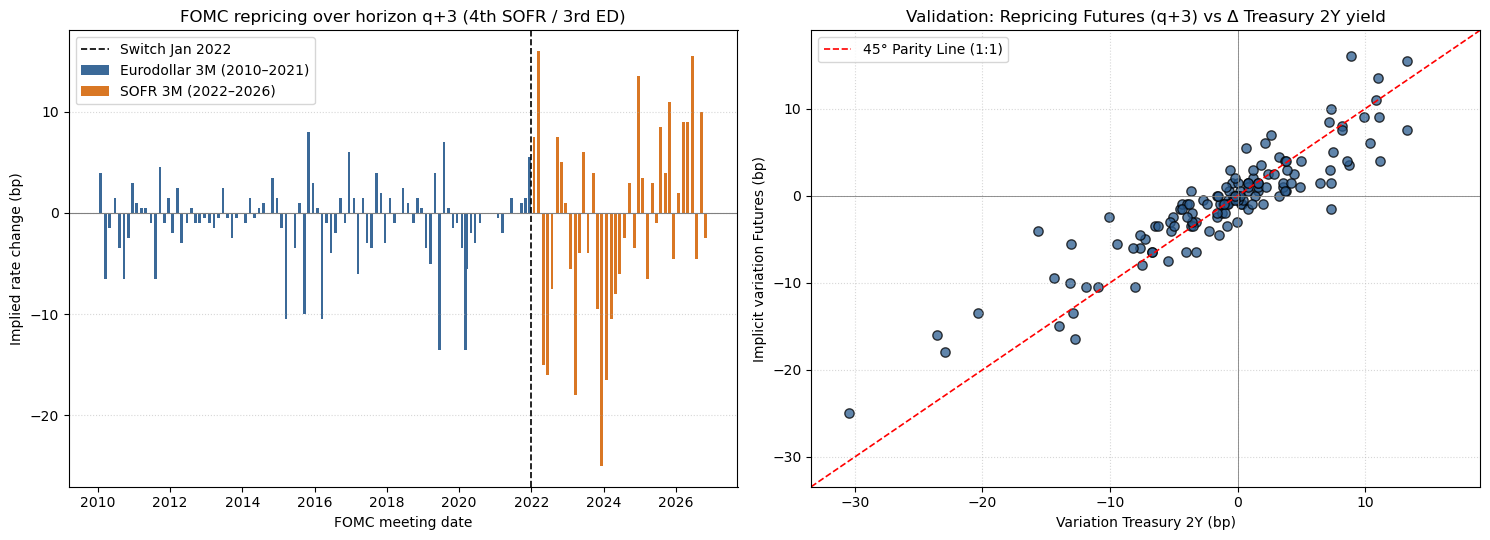

In [9]:
# Exporting CSV 
cols_team = [
    'observation_date',
    'fomc_meeting_date',
    'contract_id',
    'instrument',
    'source',
    'futures_price',
    'implied_rate_pct',
    'expected_change_bp'
]
output_csv_path = '../data/sofr_ed_fomc_repricing.csv'
df_repricing[cols_team].to_csv(output_csv_path, index=False)



fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

df_ed3 = df_repricing[df_repricing['horizon_bucket'] == 'ED3_equiv'].copy()
df_ed3['dt'] = pd.to_datetime(df_ed3['fomc_meeting_date'])

ed_part = df_ed3[df_ed3['instrument'] == 'Eurodollar_3M']
sofr_part = df_ed3[df_ed3['instrument'] == 'SOFR_3M']

axes[0].bar(ed_part['dt'], ed_part['expected_change_bp'], width=28, color='#3B6998', label='Eurodollar 3M (2010–2021)')
axes[0].bar(sofr_part['dt'], sofr_part['expected_change_bp'], width=28, color='#D97724', label='SOFR 3M (2022–2026)')
axes[0].axvline(pd.Timestamp('2022-01-01'), color='black', linestyle='--', linewidth=1.2, label='Switch Jan 2022')
axes[0].axhline(0, color='gray', linewidth=0.8)
axes[0].set_title('FOMC repricing over horizon q+3 (4th SOFR / 3rd ED)')
axes[0].set_ylabel('Implied rate change (bp)')
axes[0].set_xlabel('FOMC meeting date')
axes[0].legend()
axes[0].grid(axis='y', linestyle=':', alpha=0.5)

# Pannello B: Validazione incrociata Repricing Futures vs Δ Treasury 2Y negli annunci FOMC
axes[1].scatter(df_val['delta_2y_bp'], df_val['ED3_equiv'], alpha=0.75, color='#2B5C8F', edgecolors='k', s=45)
lims = [
    min(df_val['delta_2y_bp'].min(), df_val['ED3_equiv'].min()) - 3,
    max(df_val['delta_2y_bp'].max(), df_val['ED3_equiv'].max()) + 3
]
axes[1].plot(lims, lims, 'r--', linewidth=1.2, label='45° Parity Line (1:1)')
axes[1].set_ylabel('Futures Implied Rate Change (bp)')
axes[1].axhline(0, color='gray', linewidth=0.6)
axes[1].axvline(0, color='gray', linewidth=0.6)
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_title('Validation: Repricing Futures (q+3) vs Δ Treasury 2Y yield')
axes[1].set_xlabel('Variation Treasury 2Y (bp)')
axes[1].set_ylabel('Implicit variation Futures (bp)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('../sofr_fomc_repricing_validation.png', dpi=300)
plt.show()